# Notebook huấn luyện Agent 02

Notebook này tập hợp **hai quá trình huấn luyện**: (1) classifier ý định bằng PyTorch trong tutorial và (2) Q-learning đối đầu agent theo luật trong assignment. Các cell dưới đây thực sự train, đánh giá và lưu kết quả; không chỉ đọc kết quả cũ.

Chọn kernel Python đã cài `requirements.txt`, rồi **Restart Kernel and Run All**. Notebook chạy được khi mở từ thư mục dự án hoặc `notebooks/`. Lần chạy mặc định huấn luyện classifier 120 epoch và Q-learning 5.000 episode với một seed. Kết quả được ghi riêng vào `ket_qua/notebook_train/`.

## 1. Chuẩn bị môi trường và tham số

Dataset classifier là dữ liệu tổng hợp trong `dataset/intent_dataset.csv`. Assignment sinh dữ liệu tương tác từ môi trường mô phỏng, không dùng CSV mua bán thật. Để chạy toàn bộ 36 lượt thí nghiệm A–E, sửa `RUN_FULL_EXPERIMENT = True`; mặc định False vì tốn thời gian.

In [1]:
from pathlib import Path
import sys, json, csv, io, html
from collections import Counter
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML

start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / 'dataset/intent_dataset.csv').exists() and (p / 'code_agent').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục du_an_agent02 hoặc notebooks/')
sys.path[:0] = [str(ROOT / 'code_agent/tutorial'), str(ROOT / 'code_agent/assignment')]
from train_intent import dataset, normalize, features, IntentNet, metrics, Router, LABELS
from agent02_experiment import Config, QLearningAgent, RuleBasedAgent, evaluate, exact_best_response, run as run_full

SEED = 42
INTENT_EPOCHS = 120
RL_EPISODES = 5000
RUN_FULL_EXPERIMENT = False
OUT = ROOT / 'ket_qua/notebook_train'
(OUT / 'intent').mkdir(parents=True, exist_ok=True)
(OUT / 'rl').mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
torch.manual_seed(SEED)
print('Thư mục dự án:', ROOT)
print('Kết quả notebook:', OUT)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| NumPy:', np.__version__)

Thư mục dự án: <PROJECT_DIR>
Kết quả notebook: <PROJECT_DIR>/ket_qua/notebook_train
Python: 3.9.6 | PyTorch: 2.8.0 | NumPy: 1.26.4


## 2. Phần A — Huấn luyện classifier ý định bằng PyTorch

Mục tiêu: phân loại một yêu cầu thuộc `ecommerce`, `tourism` hoặc `healthcare_admin`. Đây là **học có giám sát**: mỗi câu có nhãn sẵn. Dữ liệu gồm 432 câu tổng hợp, chia theo nhóm động từ; một số đối tượng vẫn được dùng chung giữa các split. Test tổng hợp không đại diện toàn bộ yêu cầu thực tế.

### 2.1 Đọc dataset và kiểm tra phân chia

Chỉ dùng train để tạo vocabulary. Validation dùng chọn epoch và ngưỡng; test chỉ dùng để đánh giá sau khi đã chọn mô hình.

In [2]:
rows = dataset()
splits = {name: [row for row in rows if row['split'] == name] for name in ('train', 'validation', 'test')}
groups = {name: {r['group'] for r in group} for name, group in splits.items()}
assert not groups['train'] & groups['validation']
assert not groups['train'] & groups['test']
assert not groups['validation'] & groups['test']
for name, group in splits.items():
    print(name, 'số câu:', len(group), '| theo nhãn:', dict(Counter(r['class'] for r in group)))
print('Ví dụ:', splits['train'][0])

train số câu: 270 | theo nhãn: {'ecommerce': 90, 'tourism': 90, 'healthcare_admin': 90}
validation số câu: 54 | theo nhãn: {'ecommerce': 18, 'tourism': 18, 'healthcare_admin': 18}
test số câu: 108 | theo nhãn: {'ecommerce': 36, 'tourism': 36, 'healthcare_admin': 36}
Ví dụ: {'text': 'tìm mua laptop cho tôi', 'label': 0, 'class': 'ecommerce', 'group': '0:0', 'split': 'train'}


### 2.2 Biểu diễn dữ liệu và kiến trúc

Chuẩn hóa chữ, tạo bag-of-words nhị phân theo vocabulary của train. Mạng `IntentNet` nhận vector và xuất ba logits: Linear → ReLU → Linear. `CrossEntropyLoss` dùng trực tiếp logits; không áp softmax trước loss.

In [3]:
vocab_words = sorted({word for row in splits['train'] for word in normalize(row['text'])})
vocab = {word: i for i, word in enumerate(vocab_words)}
data = {name: (features([r['text'] for r in group], vocab), torch.tensor([r['label'] for r in group], dtype=torch.long)) for name, group in splits.items()}
model = IntentNet(len(vocab))
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
criterion = nn.CrossEntropyLoss()
print('Vocabulary:', len(vocab), '| train tensor:', tuple(data['train'][0].shape))
print(model)

Vocabulary: 79 | train tensor: (270, 79)
IntentNet(
  (net): Sequential(
    (0): Linear(in_features=79, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=3, bias=True)
  )
)


### 2.3 Vòng huấn luyện thực tế

Mỗi epoch thực hiện forward, tính loss, backpropagation và cập nhật trọng số. Chọn checkpoint theo validation loss nhỏ nhất; trạng thái được sao chép để không bị các epoch sau thay đổi.

In [4]:
history = []
best_loss = float('inf')
best_state = None
for epoch in range(INTENT_EPOCHS):
    model.train()
    optimizer.zero_grad()
    logits = model(data['train'][0])
    loss = criterion(logits, data['train'][1])
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.inference_mode():
        val_loss = float(criterion(model(data['validation'][0]), data['validation'][1]))
    history.append({'epoch': epoch + 1, 'train_loss': float(loss.detach()), 'validation_loss': val_loss})
    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch + 1
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
model.eval()
print('Số epoch:', INTENT_EPOCHS, '| epoch được chọn:', best_epoch)
print('Loss train cuối:', round(history[-1]['train_loss'], 5), '| validation tốt nhất:', round(best_loss, 5))

Số epoch: 120 | epoch được chọn: 120
Loss train cuối: 0.0 | validation tốt nhất: 0.00308


### 2.4 Chọn ngưỡng trên validation và đánh giá test

Chọn trong các ngưỡng định sẵn một ngưỡng có số mẫu được chấp nhận cao nhất và không có lỗi quan sát trên validation. Sau đó báo accuracy, precision, recall, F1 và confusion matrix trên test. Confidence không phải bảo đảm đúng ngoài miền.

In [5]:
with torch.inference_mode():
    val_probs = model(data['validation'][0]).softmax(1).numpy()
    test_probs = model(data['test'][0]).softmax(1).numpy()
choices = []
for threshold in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99):
    accepted = val_probs.max(1) >= threshold
    if accepted.any() and np.all(val_probs.argmax(1)[accepted] == data['validation'][1].numpy()[accepted]):
        choices.append((int(accepted.sum()), threshold))
threshold = max(choices, key=lambda x: (x[0], -x[1]))[1] if choices else 1.0
y_true = data['test'][1].numpy()
y_pred = test_probs.argmax(1)
report = metrics(y_true, y_pred)
accepted = test_probs.max(1) >= threshold
print('Threshold:', threshold, '| test coverage:', round(float(accepted.mean()), 3))
print('Accuracy:', round(report['accuracy'], 3), '| macro F1:', round(report['macro_f1'], 3))
for i, label in enumerate(LABELS):
    print(label, 'precision=', round(report['precision'][i], 3), 'recall=', round(report['recall'][i], 3), 'F1=', round(report['f1'][i], 3))
print('Confusion matrix:', report['confusion_matrix'])

Threshold: 0.5 | test coverage: 1.0
Accuracy: 1.0 | macro F1: 1.0
ecommerce precision= 1.0 recall= 1.0 F1= 1.0
tourism precision= 1.0 recall= 1.0 F1= 1.0
healthcare_admin precision= 1.0 recall= 1.0 F1= 1.0
Confusion matrix: [[36, 0, 0], [0, 36, 0], [0, 0, 36]]


### 2.5 Lưu checkpoint, lịch sử và biểu đồ

Checkpoint lưu `state_dict`, vocabulary và threshold để router tải lại. Tất cả được lưu riêng trong `ket_qua/notebook_train/intent/`.

Đã lưu checkpoint, CSV, metrics và biểu đồ tại <PROJECT_DIR>/ket_qua/notebook_train/intent


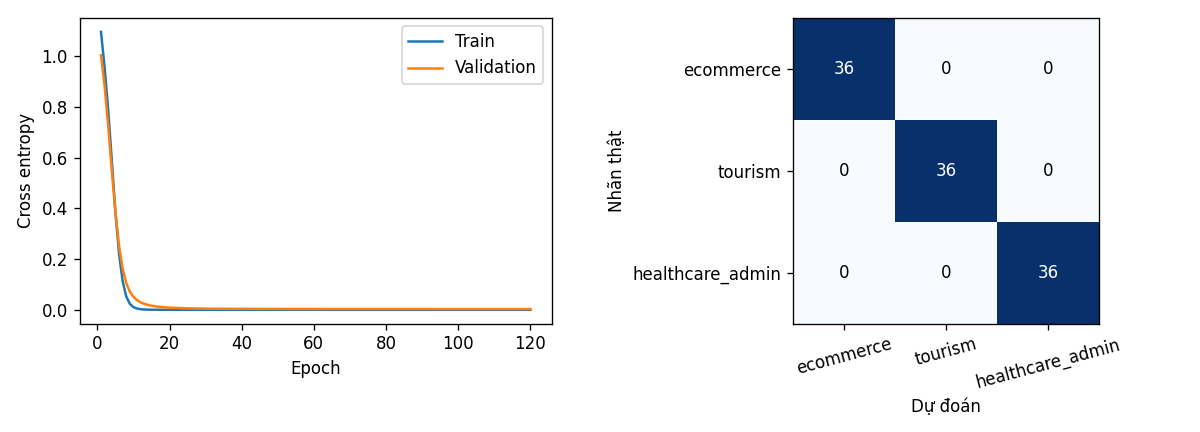

In [6]:
torch.save({'state_dict': best_state, 'vocab': vocab, 'threshold': threshold}, OUT / 'intent/intent_model.pt')
with (OUT / 'intent/history.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0])); writer.writeheader(); writer.writerows(history)
with (OUT / 'intent/test_predictions.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=['text', 'true_label', 'predicted', 'confidence', 'accepted']); writer.writeheader()
    for row, pred, probs in zip(splits['test'], y_pred, test_probs):
        writer.writerow({'text': row['text'], 'true_label': row['label'], 'predicted': int(pred), 'confidence': float(probs.max()), 'accepted': bool(probs.max() >= threshold)})
(OUT / 'intent/metrics.json').write_text(json.dumps({'accuracy': report['accuracy'], 'macro_f1': report['macro_f1'], 'precision': report['precision'], 'recall': report['recall'], 'f1': report['f1'], 'confusion_matrix': report['confusion_matrix'], 'threshold': threshold, 'test_coverage': float(accepted.mean()), 'selected_epoch': best_epoch}, ensure_ascii=False, indent=2), encoding='utf-8')
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot([r['epoch'] for r in history], [r['train_loss'] for r in history], label='Train')
ax[0].plot([r['epoch'] for r in history], [r['validation_loss'] for r in history], label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Cross entropy'); ax[0].legend()
cm = np.array(report['confusion_matrix']); ax[1].imshow(cm, cmap='Blues')
ax[1].set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS, xlabel='Dự đoán', ylabel='Nhãn thật')
ax[1].tick_params(axis='x', rotation=15)
for i in range(3):
    for j in range(3):
        ax[1].text(j, i, str(cm[i,j]), ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig(OUT/'intent/training.png', dpi=150)
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=120); plt.close(fig); display(Image(data=buf.getvalue()))
print('Đã lưu checkpoint, CSV, metrics và biểu đồ tại', OUT / 'intent')

### 2.6 Thử câu ngoài miền

Router dùng checkpoint vừa train và cơ chế từ chối đơn giản. Kết quả được in trực tiếp, kể cả những câu ngoài miền bị định tuyến sai.

In [7]:
router = Router(OUT/'intent')
for text in ['tìm mua laptop cho tôi', 'xin chào', 'thời tiết hôm nay thế nào', 'giải phương trình']:
    print(repr(text), '→', router.route(text))

'tìm mua laptop cho tôi' → {'intent': 'ecommerce', 'confidence': 0.9999960660934448}
'xin chào' → {'intent': 'clarify', 'confidence': 0.49433353543281555}
'thời tiết hôm nay thế nào' → {'intent': 'ecommerce', 'confidence': 0.9876664876937866}
'giải phương trình' → {'intent': 'tourism', 'confidence': 0.9311287999153137}


## 3. Phần B — Huấn luyện Q-learning cho assignment

Hai cửa hàng chọn đồng thời: 0 không giảm giá, 1 giảm 20%. Observation là `(nhu cầu, hành động trước của đối thủ)`. Reward là lợi nhuận mô phỏng. Đối thủ là rule-based cố định. Mô hình này có giới hạn: observation không chứa hành động trước của chính learner và bảng Q không chứa thời gian còn lại.

### 3.1 Cập nhật Q-learning

Với transition chưa kết thúc:

$$Q(s,a) \leftarrow Q(s,a)+\alpha\left[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\right].$$

Ở bước cuối, target chỉ bằng reward. Epsilon-greedy thử ngẫu nhiên với xác suất epsilon, còn lại chọn action có Q lớn nhất.

In [8]:
cfg = Config(episodes=RL_EPISODES)
print(cfg)
example = QLearningAgent(cfg)
example.q[0,0,0] = 4.0
example.q[1,1] = [5.0, 2.0]
example.learn((0,0), 0, 6, (1,1))
print('Ví dụ đề bài: Q mới =', example.q[0,0,0])
assert np.isclose(example.q[0,0,0], 4.65)

Config(episodes=5000, horizon=20, evaluation_episodes=500, alpha=0.1, gamma=0.9, epsilon_start=0.2, epsilon_min=0.02, epsilon_decay=0.995, price=10.0, cost=5.0, discount=0.2)
Ví dụ đề bài: Q mới = 4.65


### 3.2 Train trực tiếp 5.000 episode

Đoạn sau thể hiện đầy đủ vòng huấn luyện: tạo RNG, lấy nhu cầu, chọn cả hai action trước khi tính reward, lấy sales binomial, cập nhật Q, lưu reward từng episode. RNG được tách cho nhu cầu, sales và hai agent theo script assignment.

In [9]:
sd, ss, sa, sb = np.random.SeedSequence(SEED).spawn(4)
demand_tape = np.random.default_rng(sd).integers(2, size=(cfg.episodes, cfg.horizon + 1))
sales_rng = np.random.default_rng(ss)
learner = QLearningAgent(cfg)
learner.rng = np.random.default_rng(sa)
rule = RuleBasedAgent()
rl_history = []
action_counts = np.zeros((2, 2), dtype=int)

for ep in range(cfg.episodes):
    previous = [0, 0]
    totals = [0.0, 0.0]
    epsilon = max(cfg.epsilon_min, cfg.epsilon_start * cfg.epsilon_decay ** ep)
    for t in range(cfg.horizon):
        d = int(demand_tape[ep, t])
        states = [(d, previous[1]), (d, previous[0])]
        action_a = learner.act(states[0], epsilon)
        action_b = rule.act(states[1])
        actions = [action_a, action_b]  # chọn đồng thời
        rewards = []
        for i in (0, 1):
            probability = 0.30 + 0.25*d + 0.15*actions[i] - 0.10*actions[1-i]
            sales = int(sales_rng.binomial(10 + 10*d, probability))
            reward = sales * (cfg.price * (1 - cfg.discount*actions[i]) - cfg.cost)
            rewards.append(reward); totals[i] += reward; action_counts[i, actions[i]] += 1
        next_states = [(int(demand_tape[ep,t+1]), action_b), (int(demand_tape[ep,t+1]), action_a)]
        learner.learn(states[0], action_a, rewards[0], next_states[0], terminal=(t == cfg.horizon-1))
        previous = actions
    rl_history.append({'episode': ep+1, 'rl_total': totals[0], 'rule_total': totals[1], 'rl_mean': totals[0]/cfg.horizon, 'rule_mean': totals[1]/cfg.horizon, 'epsilon': epsilon})

print('Hoàn tất', len(rl_history), 'episode,', len(rl_history)*cfg.horizon, 'bước')
print('Số action [không giảm, giảm]:', action_counts.tolist())
print('Q-table:\n', learner.q)

Hoàn tất 5000 episode, 100000 bước
Số action [không giảm, giảm]: [[86134, 13866], [93446, 6554]]
Q-table:
 [[[184.21286701 199.4490361 ]
  [221.95604665 181.66800997]]

 [[227.27976083 235.19751263]
  [197.47170098 218.16258916]]]


### 3.3 Đường reward và lưu dữ liệu training

Reward được làm trơn qua 100 episode. Đường training bao gồm exploration và nhiễu của nhu cầu/doanh số, nên không tự chứng minh hội tụ.

Đã lưu training.csv, q_table.npy và training.png


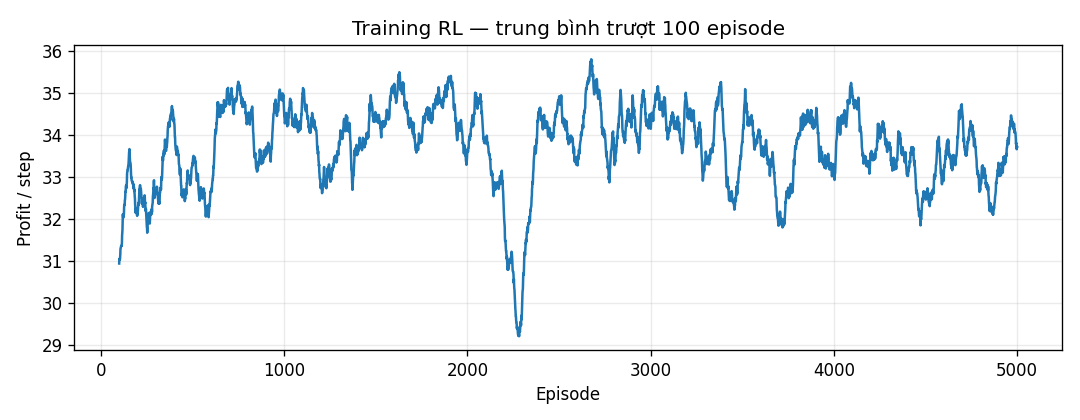

In [10]:
with (OUT/'rl/training.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(rl_history[0])); writer.writeheader(); writer.writerows(rl_history)
np.save(OUT/'rl/q_table.npy', learner.q)
window = min(100, len(rl_history))
curve = np.convolve([r['rl_mean'] for r in rl_history], np.ones(window)/window, mode='valid')
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(np.arange(window, window+len(curve)), curve)
ax.set(xlabel='Episode', ylabel='Profit / step', title=f'Training RL — trung bình trượt {window} episode')
ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(OUT/'rl/training.png', dpi=150)
buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=120); plt.close(fig); display(Image(data=buf.getvalue()))
print('Đã lưu training.csv, q_table.npy và training.png')

### 3.4 Đánh giá policy đóng băng và so sánh công bằng

Q không cập nhật, epsilon = 0. Cùng evaluation seed được dùng cho policy RL và policy không giảm giá; cả hai đối đầu cùng rule-based opponent. Kiểm tra bằng assertion rằng Q-table không thay đổi.

In [11]:
frozen_q = learner.q.copy()
rl_eval, rl_episodes = evaluate(cfg, learner.q, seed=500042)
never_eval, _ = evaluate(cfg, 'never', seed=500042)
assert np.array_equal(frozen_q, learner.q)
for name, summary in [('RL', rl_eval[0]), ('Không giảm', never_eval[0]), ('Rule đối thủ trong trận RL', rl_eval[1])]:
    print(name, '| total:', summary['total_reward'], '| reward/step:', round(summary['mean_reward'],4), '| discount rate:', round(summary['discount_rate'],4))
with (OUT/'rl/evaluation.csv').open('w',newline='',encoding='utf-8') as f:
    writer=csv.DictWriter(f,fieldnames=list(rl_episodes[0]));writer.writeheader();writer.writerows(rl_episodes)
(OUT/'rl/evaluation_summary.json').write_text(json.dumps({'rl_vs_rule':rl_eval,'never_vs_rule':never_eval,'seed':500042},indent=2),encoding='utf-8')

RL | total: 255591.0 | reward/step: 25.5591 | discount rate: 0.8151
Không giảm | total: 348295.0 | reward/step: 34.8295 | discount rate: 0.0
Rule đối thủ trong trận RL | total: 246856.0 | reward/step: 24.6856 | discount rate: 0.3853
Out[11]: 940


### 3.5 Mốc quy hoạch động

Trong mô hình nhỏ và biết trước reward/chuyển trạng thái, quy hoạch động dùng full state và thời gian là oracle so sánh. Kết quả chỉ có ý nghĩa trong mô hình đã giả định.

In [12]:
oracle_policy, oracle_values = exact_best_response(cfg)
oracle_eval, _ = evaluate(cfg, oracle_policy, seed=500042)
print('Oracle chọn không giảm ở mọi state/time:', bool((oracle_policy == 0).all()))
print('Oracle reward / bước:', round(oracle_eval[0]['mean_reward'],4))

Oracle chọn không giảm ở mọi state/time: True
Oracle reward / bước: 34.8295


## 4. Toàn bộ thí nghiệm alpha, epsilon, nhiều seed và self-play

Hàm `run_full` từ `code_agent/assignment/agent02_experiment.py` thực hiện 36 lần huấn luyện: 25 cấu hình/seed, một baseline seed 42, năm lần retrain khi discount 40% và năm lần self-play. Các kết quả lưu riêng trong `ket_qua/notebook_train/assignment_full/`. Chỉ bật cờ ở cell đầu nếu muốn chạy lại; mặc định xem bảng đã đo từ báo cáo.

In [13]:
if RUN_FULL_EXPERIMENT:
    full_result = run_full(output=OUT/'assignment_full', episodes=5000)
    print('Hoàn tất suite tại', OUT/'assignment_full')
else:
    print('Không chạy suite đầy đủ; đang đọc bảng đã đo trước từ ket_qua/assignment/aggregate.csv.')
    with (ROOT/'ket_qua/assignment/aggregate.csv').open(encoding='utf-8',newline='') as f:
        aggregate = list(csv.DictReader(f))
    for row in aggregate:
        print(row['configuration'], '| eval mean=', round(float(row['mean']),4), '| SD=', round(float(row['sd']),4), '| discount rate=', round(float(row['discount_rate']),4))

Không chạy suite đầy đủ; đang đọc bảng đã đo trước từ ket_qua/assignment/aggregate.csv.
baseline | eval mean= 34.0997 | SD= 1.3678 | discount rate= 0.1616
alpha_001 | eval mean= 33.6484 | SD= 2.1286 | discount rate= 0.1991
alpha_050 | eval mean= 31.9533 | SD= 4.1613 | discount rate= 0.3808
epsilon_005 | eval mean= 33.3973 | SD= 1.6126 | discount rate= 0.279
epsilon_030 | eval mean= 31.43 | SD= 3.9272 | discount rate= 0.3388


## 5. Cách đọc và giới hạn kết quả

- PyTorch là phân loại có giám sát trên dữ liệu tổng hợp; Q-learning học từ reward mô phỏng. Hai quá trình dùng dữ liệu và mục tiêu khác nhau.
- Kết quả Q-learning trong cell training là **một seed 42**. Bảng nhiều seed ở mục 4 phù hợp hơn để xem biến động giữa các lượt huấn luyện.
- Accuracy cao trên dataset tổng hợp không bảo đảm nhận diện tốt ngoài miền. Một policy RL tốt trên mô hình toy không chứng minh hiệu quả trong thị trường thật.
- Có thể chỉnh seed, số epoch, số episode hoặc `RUN_FULL_EXPERIMENT` ở cell đầu. Kết quả ghi trong `ket_qua/notebook_train/`, không ghi đè bộ kết quả trong báo cáo.